# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site 2013–2017)
- **Nama:** Jason Adriel Gerard Abidano
- **Email:** jason01012006@gmail.com / ds014b6y0826@student.devacademy.id
- **ID Dicoding:** ds014b6y0826

## Menentukan Pertanyaan Bisnis

Berdasarkan eksplorasi konteks pada **[Beijing Multi-Site Air Quality Dataset (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data)** yang diakses melalui Google Drive ([PRSA_Data_20130301-20170228](https://drive.google.com/drive/folders/1G6a79gLjlo-87N0E15Nmt65DzROxus_X) / [Air-quality-dataset.zip](https://drive.google.com/file/d/1RhU3gJlkteaAQfyn9XOVAz7a5o1-etgr/view?usp=drivesdk), mencakup 12 stasiun pemantauan udara dari 1 Maret 2013 hingga 28 Februari 2017), berikut adalah **3 Pertanyaan Bisnis** yang dirumuskan menggunakan metode **SMART** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

1. **Pertanyaan 1 (Perbandingan Spasial & Tren Tahunan Stasiun):**
   > *"Stasiun pemantauan mana di antara 12 lokasi di Beijing yang memiliki rata-rata konsentrasi polutan partikulat (`PM2.5` dan `PM10`) tertinggi dan terendah, serta berapa persentase perbedaan tingkat polusi antara zona **Urban (Pusat Kota)** dan **Suburban (Pinggiran/Utara)** sepanjang periode Maret 2013 hingga Februari 2017?"*
   - **Specific:** Berfokus pada perbandingan konsentrasi `PM2.5` dan `PM10` antar 12 stasiun pemantauan serta komparasi zona *Urban* vs *Suburban* di Beijing.
   - **Measurable:** Diukur menggunakan rata-rata konsentrasi (`µg/m³`), persentase selisih antar-zona (`%`), serta proporsi jam tidak sehat (`PM2.5 > 55.4 µg/m³`).
   - **Action-Oriented:** Menentukan stasiun/distrik prioritas utama untuk penempatan penyaring udara publik, pembatasan emisi kendaraan bermotor (*Low Emission Zone*), dan inspeksi industri.
   - **Relevant:** Mengidentifikasi titik panas (*hotspot*) polusi secara presisi agar alokasi anggaran pengendalian polusi udara tepat sasaran.
   - **Time-bound:** Dibatasi secara jelas pada periode observasi dataset **1 Maret 2013 – 28 Februari 2017** (serta evaluasi tahun kalender penuh **2014–2016**).

2. **Pertanyaan 2 (Pola Musiman & Jam Kritis Harian):**
   > *"Bagaimana pola fluktuasi musiman (bulanan) dan jam puncak harian (00:00–23:00) memengaruhi lonjakan konsentrasi polutan primer (`PM2.5`, `NO2`, `CO`) serta polutan sekunder (`O3`) di Beijing selama periode Maret 2013 hingga Februari 2017?"*
   - **Specific:** Mengkaji variasi konsentrasi polutan berdasarkan siklus bulanan/musiman (*Spring, Summer, Autumn, Winter*) dan jam harian (*diurnal cycle* 24 jam).
   - **Measurable:** Diukur dari rata-rata konsentrasi polutan (`µg/m³`) pada setiap bulan (1–12) dan setiap jam (0–23), serta persentase lonjakan musim dingin terhadap musim panas.
   - **Action-Oriented:** Memberikan jadwal waktu spesifik bagi pemerintah dan masyarakat terkait kapan harus mengaktifkan peringatan dini (*early warning*), membatasi pembakaran batu bara pemanas ruangan, dan menghindari aktivitas luar ruang.
   - **Relevant:** Polusi udara di Beijing sangat dipengaruhi oleh pemanas batu bara musim dingin dan jam sibuk lalu lintas harian.
   - **Time-bound:** Mencakup rentang waktu **Maret 2013 – Februari 2017**.

3. **Pertanyaan 3 (Dampak Faktor Meteorologi terhadap Dispersi Polutan):**
   > *"Seberapa besar pengaruh faktor meteorologi—khususnya kecepatan angin (`WSPM`), curah hujan (`RAIN`), dan suhu udara (`TEMP`)—terhadap penurunan konsentrasi `PM2.5` di seluruh stasiun Beijing selama periode Maret 2013 hingga Februari 2017?"*
   - **Specific:** Menganalisis korelasi dan dampak rezim kecepatan angin (`WSPM`), curah hujan (`RAIN`), dan suhu (`TEMP`) terhadap konsentrasi `PM2.5`.
   - **Measurable:** Diukur menggunakan koefisien korelasi Pearson (`r`) dan persentase penurunan rata-rata `PM2.5` (`µg/m³`) antar kelompok kecepatan angin (*Calm* `<=1.0 m/s` hingga *Strong Wind* `>4.0 m/s`).
   - **Action-Oriented:** Menjadi dasar ilmiah untuk sistem peringatan dini berbasis prakiraan cuaca (mengaktifkan pembatasan emisi darurat sebelum periode angin tenang/*stagnan* `WSPM <= 1.0 m/s` terjadi).
   - **Relevant:** Kondisi meteorologi menentukan apakah polutan terperangkap di permukaan tanah (*inversi termal*) atau terdispersi ke atmosfer.
   - **Time-bound:** Periode observasi **1 Maret 2013 – 28 Februari 2017**.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi tampilan tabel dan visualisasi
pd.set_option('display.max_columns', None)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid")
print("Seluruh library berhasil dimuat!")

Seluruh library berhasil dimuat!

## Data Wrangling

### Gathering Data
Pada tahap **Gathering Data**, kita mengumpulkan dan memuat seluruh 12 file CSV stasiun pemantauan kualitas udara dari direktori `PRSA_Data_20130301-20170228` (yaitu *Aotizhongxin, Changping, Dingling, Dongsi, Guanyuan, Gucheng, Huairou, Nongzhanguan, Shunyi, Tiantan, Wanliu,* dan *Wanshouxigong*), lalu menggabungkannya ke dalam satu `DataFrame` utuh.

In [2]:
# Memuat seluruh 12 file CSV stasiun pemantauan di Beijing
data_dir = "data"  # Sesuaikan dengan path folder dataset PRSA_Data_20130301-20170228
csv_files = sorted(glob.glob(os.path.join(data_dir, "PRSA_Data_*.csv")))

df_list = []
for file_path in csv_files:
    df_station = pd.read_csv(file_path)
    df_list.append(df_station)

raw_df = pd.concat(df_list, ignore_index=True)
print(f"Jumlah file stasiun yang dimuat : {len(csv_files)} stasiun")
print(f"Ukuran total DataFrame gabungan : {raw_df.shape[0]:,} baris x {raw_df.shape[1]} kolom")
raw_df.head()

Jumlah file stasiun yang dimuat : 12 stasiun
Ukuran total DataFrame gabungan : 420,768 baris x 18 kolom
   No  year  month  day  hour  PM2.5  PM10   SO2   NO2     CO    O3  TEMP    PRES  DEWP  RAIN   wd  WSPM       station
0   1  2013      3    1     0    4.0   4.0   4.0   7.0  300.0  77.0  -0.7  1023.0 -18.8   0.0  NNW   4.4  Aotizhongxin
1   2  2013      3    1     1    8.0   8.0   4.0   7.0  300.0  77.0  -1.1  1023.2 -18.2   0.0    N   4.7  Aotizhongxin
2   3  2013      3    1     2    7.0   7.0   5.0  10.0  300.0  73.0  -1.1  1023.5 -18.2   0.0  NNW   5.6  Aotizhongxin
3   4  2013      3    1     3    6.0   6.0  11.0  11.0  300.0  72.0  -1.4  1024.5 -19.4   0.0   NW   3.1  Aotizhongxin
4   5  2013      3    1     4    3.0   3.0  12.0  12.0  300.0  72.0  -2.0  1025.2 -19.5   0.0    N   2.0  Aotizhongxin

**Insight Gathering Data:**
- Dataset berhasil digabungkan dari **12 stasiun pemantauan** dengan masing-masing stasiun memiliki **35.064 baris** data per jam (1 Maret 2013 pukul 00:00 hingga 28 Februari 2017 pukul 23:00), sehingga total keseluruhan data berjumlah **420.768 baris** dan **18 kolom**.
- Atribut data terdiri atas komponen waktu (`year`, `month`, `day`, `hour`), 6 polutan udara (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), 6 variabel meteorologi (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`), serta nama stasiun (`station`).

### Assessing Data
Pada tahap **Assessing Data**, kita memeriksa kualitas dan struktur data untuk mengidentifikasi permasalahan seperti:
1. **Missing Value** (nilai kosong/`NaN`)
2. **Duplicate Data** (baris duplikat maupun duplikasi penomoran `No` antar-stasiun)
3. **Inconsistent / Invalid Data Type** (kolom waktu masih terpisah menjadi 4 kolom integer dan belum bertipe `datetime64[ns]`)
4. **Outlier / Extreme Value** menggunakan metode *Interquartile Range* (IQR).

In [3]:
# 1. Memeriksa informasi tipe data dan jumlah missing value
missing_count = raw_df.isna().sum()
missing_pct = (raw_df.isna().mean() * 100).round(2)
assess_df = pd.DataFrame({
    'Tipe Data': raw_df.dtypes,
    'Jumlah Missing': missing_count,
    'Persentase Missing (%)': missing_pct
})
print("=== RINGKASAN TIPE DATA & MISSING VALUES ===")
print(assess_df)
print(f"\nJumlah baris duplikat penuh      : {raw_df.duplicated().sum()}")
print(f"Jumlah duplikasi kombinasi waktu : {raw_df.duplicated(subset=['station', 'year', 'month', 'day', 'hour']).sum()}")

=== RINGKASAN TIPE DATA & MISSING VALUES ===
        Tipe Data  Jumlah Missing  Persentase Missing (%)
No          int64               0                    0.00
year        int64               0                    0.00
month       int64               0                    0.00
day         int64               0                    0.00
hour        int64               0                    0.00
PM2.5     float64            8739                    2.08
PM10      float64            6449                    1.53
SO2       float64            9021                    2.14
NO2       float64           12116                    2.88
CO        float64           20701                    4.92
O3        float64           13277                    3.16
TEMP      float64             398                    0.09
PRES      float64             393                    0.09
DEWP      float64             403                    0.10
RAIN      float64             390                    0.09
wd         object          

In [4]:
# 2. Memeriksa statistik deskriptif dan mengidentifikasi Outlier menggunakan metode IQR
num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
outlier_rows = []
for col in num_cols:
    s = raw_df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({
        'Fitur': col,
        'Min': round(s.min(), 2),
        'Q1 (25%)': round(q1, 2),
        'Median (50%)': round(s.median(), 2),
        'Q3 (75%)': round(q3, 2),
        'Max': round(s.max(), 2),
        'Batas Atas IQR': round(upper, 2),
        'Jumlah Outlier': n_out,
        'Persentase Outlier (%)': round(n_out / len(s) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_rows)
print("=== IDENTIFIKASI OUTLIER & NILAI EKSTREM (METODE IQR) ===")
print(outlier_df.to_string(index=False))

=== IDENTIFIKASI OUTLIER & NILAI EKSTREM (METODE IQR) ===
Fitur    Min  Q1 (25%)  Median (50%)  Q3 (75%)      Max  Batas Atas IQR  Jumlah Outlier  Persentase Outlier (%)
PM2.5   2.00      20.0          55.0     111.0    999.0          247.50           19142                    4.65
 PM10   2.00      36.0          82.0     145.0    999.0          308.50           14658                    3.54
  SO2   0.29       3.0           7.0      20.0    500.0           45.50           35566                    8.64
  NO2   1.03      23.0          43.0      71.0    290.0          143.00            7021                    1.72
   CO 100.00     500.0         900.0    1500.0  10000.0         3000.00           28054                    7.01
   O3   0.21      11.0          45.0      82.0   1071.0          188.50           16599                    4.07
 TEMP -19.90       3.1          14.5      23.3     41.6           53.60               0                    0.00
 PRES 982.40    1002.3        1010.4    1019.0

**Insight Assessing Data & Rencana Solusi Pembersihan (Cleaning Plan):**

| No | Permasalahan Data yang Ditemukan | Detail Temuan pada Dataset | Solusi / Tindakan pada Tahap Cleaning Data |
| :- | :--- | :--- | :--- |
| **1** | **Missing Values (Nilai Kosong)** | Terdapat nilai kosong pada 12 kolom: `CO` (20.701 baris / 4,92%), `O3` (13.277 / 3,16%), `NO2` (12.116 / 2,88%), `SO2` (9.021 / 2,14%), `PM2.5` (8.739 / 2,08%), `PM10` (6.449 / 1,53%), variabel cuaca `TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM` (318–403 baris / ~0,09%), dan kolom kategorikal arah angin `wd` (1.822 baris / 0,43%). | Karena data bersifat *time-series* berurutan per jam di tiap stasiun, kolom numerik diisi menggunakan **interpolasi linier per stasiun** (`.interpolate(method='linear')`) yang dilengkapi `.bfill()` dan `.ffill()`. Untuk kolom kategorikal `wd` (arah angin), diisi menggunakan `.ffill().bfill()` per stasiun. |
| **2** | **Inconsistent / Redundant Columns & Tipe Data Waktu** | Waktu pengamatan masih terpecah menjadi 4 kolom integer (`year`, `month`, `day`, `hour`) dan terdapat kolom `No` yang berulang (`1–35.064`) di setiap stasiun. | Menggabungkan `year`, `month`, `day`, `hour` menjadi satu kolom `datetime` bertipe `datetime64[ns]`, mengurutkan berdasarkan `['station', 'datetime']`, dan menghapus kolom redundan `No`. |
| **3** | **Outliers / Extreme Values pada Polutan** | Terdapat *outlier* secara statistik (mis. `PM2.5 > 247.5 µg/m³` sebanyak 4,65% dengan nilai maksimum `999.0 µg/m³`). Dalam domain kualitas udara Beijing, lonjakan ekstrem saat musim dingin merupakan fenomena *heavy smog* nyata (kategori *Hazardous* `> 250.4 µg/m³`) yang tidak boleh dihapus sembarangan karena justru menjadi objek analisis utama. | Mempertahankan rekaman lonjakan polusi historis agar analisis gelombang kabut asap (*smog*) tetap akurat, serta mengelompokkannya secara terstruktur menggunakan teknik **Binning Kategori AQI** pada tahap analisis lanjutan. |

### Cleaning Data
Pada tahap **Cleaning Data**, kita mengeksekusi seluruh rencana pembersihan di atas dan memverifikasi bahwa dataset telah bersih (`0` *missing values* dan `0` duplikat).

In [5]:
# Menyalin DataFrame mentah untuk proses pembersihan
df_clean = raw_df.copy()

# 1. Membuat kolom datetime terpadu dan menghapus kolom redundan 'No'
df_clean['datetime'] = pd.to_datetime(df_clean[['year', 'month', 'day', 'hour']])
df_clean = df_clean.sort_values(['station', 'datetime']).reset_index(drop=True)
df_clean = df_clean.drop(columns=['No'])

# 2. Menangani missing values pada kolom numerik dengan interpolasi linier per stasiun
for col in num_cols:
    df_clean[col] = df_clean.groupby('station')[col].transform(
        lambda s: s.interpolate(method='linear').bfill().ffill()
    )

# 3. Menangani missing values pada kolom kategorikal arah angin (wd) per stasiun
df_clean['wd'] = df_clean.groupby('station')['wd'].transform(lambda s: s.ffill().bfill())

# 4. Menambahkan fitur turunan untuk mendukung EDA dan Analisis Lanjutan
urban_stations = ['Dongsi', 'Tiantan', 'Nongzhanguan', 'Guanyuan', 'Wanliu', 'Aotizhongxin', 'Wanshouxigong', 'Gucheng']
df_clean['station_zone'] = np.where(
    df_clean['station'].isin(urban_stations),
    'Urban (Pusat Kota)',
    'Suburban (Pinggiran/Utara)'
)

season_map = {
    12: 'Winter (Des-Feb)', 1: 'Winter (Des-Feb)', 2: 'Winter (Des-Feb)',
    3: 'Spring (Mar-Mei)', 4: 'Spring (Mar-Mei)', 5: 'Spring (Mar-Mei)',
    6: 'Summer (Jun-Agu)', 7: 'Summer (Jun-Agu)', 8: 'Summer (Jun-Agu)',
    9: 'Autumn (Sep-Nov)', 10: 'Autumn (Sep-Nov)', 11: 'Autumn (Sep-Nov)'
}
df_clean['season'] = df_clean['month'].map(season_map)

print("Total missing values setelah Cleaning :", df_clean.isna().sum().sum())
print("Ukuran DataFrame setelah Cleaning     :", df_clean.shape)
df_clean[['datetime', 'station', 'station_zone', 'season', 'PM2.5', 'PM10', 'NO2', 'CO', 'O3', 'TEMP', 'WSPM', 'wd']].head()

Total missing values setelah Cleaning : 0
Ukuran DataFrame setelah Cleaning     : (420768, 20)
             datetime       station        station_zone            season  PM2.5  PM10   NO2     CO    O3  TEMP  WSPM   wd
0 2013-03-01 00:00:00  Aotizhongxin  Urban (Pusat Kota)  Spring (Mar-Mei)    4.0   4.0   7.0  300.0  77.0  -0.7   4.4  NNW
1 2013-03-01 01:00:00  Aotizhongxin  Urban (Pusat Kota)  Spring (Mar-Mei)    8.0   8.0   7.0  300.0  77.0  -1.1   4.7    N
2 2013-03-01 02:00:00  Aotizhongxin  Urban (Pusat Kota)  Spring (Mar-Mei)    7.0   7.0  10.0  300.0  73.0  -1.1   5.6  NNW
3 2013-03-01 03:00:00  Aotizhongxin  Urban (Pusat Kota)  Spring (Mar-Mei)    6.0   6.0  11.0  300.0  72.0  -1.4   3.1   NW
4 2013-03-01 04:00:00  Aotizhongxin  Urban (Pusat Kota)  Spring (Mar-Mei)    3.0   3.0  12.0  300.0  72.0  -2.0   2.0    N

## Exploratory Data Analysis (EDA)

### 1. Eksplorasi Perbandingan Polutan Antar-Stasiun & Zona Wilayah (Menjawab Pertanyaan 1)
Kita melakukan agregasi statistik (`mean`, `median`, dan persentase jam tidak sehat `PM2.5 > 55.4 µg/m³`) pada ke-12 stasiun pemantauan serta membandingkan zona **Urban (Pusat Kota)** dengan **Suburban (Pinggiran/Utara)**.

In [6]:
# Agregasi tingkat polutan per stasiun dan zona wilayah
station_eda = df_clean.groupby(['station', 'station_zone']).agg(
    PM25_Mean=('PM2.5', 'mean'),
    PM25_Median=('PM2.5', 'median'),
    PM10_Mean=('PM10', 'mean'),
    NO2_Mean=('NO2', 'mean'),
    CO_Mean=('CO', 'mean'),
    O3_Mean=('O3', 'mean'),
    Unhealthy_Hours_Pct=('PM2.5', lambda s: (s > 55.4).mean() * 100)
).round(2).sort_values(by='PM25_Mean', ascending=False)

print("=== PERINGKAT 12 STASIUN BERDASARKAN RATA-RATA PM2.5 (2013-2017) ===")
print(station_eda.to_string())

print("\n=== PERBANDINGAN RATA-RATA POLUTAN ZONA URBAN VS SUBURBAN ===")
zone_eda = df_clean.groupby('station_zone')[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']].mean().round(2)
print(zone_eda.to_string())

=== PERINGKAT 12 STASIUN BERDASARKAN RATA-RATA PM2.5 (2013-2017) ===
                                         PM25_Mean  PM25_Median  PM10_Mean  NO2_Mean  CO_Mean  O3_Mean  Unhealthy_Hours_Pct
station       station_zone                                                                                                 
Dongsi        Urban (Pusat Kota)             86.14         61.0     110.35     53.95  1331.91    57.70                53.11
Nongzhanguan  Urban (Pusat Kota)             85.08         59.0     109.38     58.10  1327.76    58.43                51.86
Wanshouxigong Urban (Pusat Kota)             85.07         60.0     112.51     55.49  1373.62    56.02                52.59
Gucheng       Urban (Pusat Kota)             84.07         60.0     119.26     55.85  1338.10    58.14                52.60
Wanliu        Urban (Pusat Kota)             83.47         59.0     110.71     65.66  1328.76    48.47                51.91
Guanyuan      Urban (Pusat Kota)             82.90         59.0

### 2. Eksplorasi Tren Tahunan, Musiman, dan Siklus Harian (Menjawab Pertanyaan 2)
Selanjutnya kita mengeksplorasi perubahan konsentrasi polutan berdasarkan tahun (`year`), musim (`season`), bulan (`month`), dan jam harian (`hour`).

In [7]:
# Agregasi per Tahun, Musim, dan Jam Puncak
print("=== RATA-RATA POLUTAN PER TAHUN (2013-2017) ===")
print(df_clean.groupby('year')[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']].mean().round(2).to_string())

print("\n=== RATA-RATA POLUTAN & CUACA PER MUSIM ===")
print(df_clean.groupby('season')[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'WSPM', 'RAIN']].mean().round(2).to_string())

print("\n=== 5 JAM DENGAN RATA-RATA PM2.5 TERTINGGI & TERENDAH ===")
hour_eda = df_clean.groupby('hour')[['PM2.5', 'PM10', 'NO2', 'CO', 'O3', 'TEMP', 'WSPM']].mean().round(2)
print("Tertinggi (Malam Hari):")
print(hour_eda.sort_values('PM2.5', ascending=False).head(5).to_string())
print("\nTerendah (Pagi & Sore Hari):")
print(hour_eda.sort_values('PM2.5', ascending=True).head(5).to_string())

=== RATA-RATA POLUTAN PER TAHUN (2013-2017) ===
      PM2.5    PM10    SO2    NO2       CO     O3
year                                             
2013  79.77  103.20  20.00  52.05  1205.31  56.26
2014  86.18  116.82  21.20  55.05  1271.12  57.90
2015  79.31  103.66  13.00  48.32  1261.92  59.29
2016  72.08   94.75   9.78  46.16  1138.02  58.13
2017  92.41  110.88  18.11  57.22  1617.49  39.95

=== RATA-RATA POLUTAN & CUACA PER MUSIM ===
                  PM2.5    PM10    SO2    NO2       CO     O3   TEMP  WSPM  RAIN
season                                                                          
Autumn (Sep-Nov)  82.21  103.39  10.07  55.63  1250.36  34.64  13.00  1.45  0.06
Spring (Mar-Mei)  77.21  120.87  18.97  50.17   984.71  71.17  15.05  2.07  0.03
Summer (Jun-Agu)  64.52   80.86   6.02  36.85   906.03  93.00  26.15  1.51  0.17
Winter (Des-Feb)  95.74  114.69  28.77  59.98  1807.50  29.36  -0.34  1.90  0.00

=== 5 JAM DENGAN RATA-RATA PM2.5 TERTINGGI & TERENDAH ===
Tertinggi (M

### 3. Eksplorasi Korelasi Faktor Meteorologi terhadap Polutan (Menjawab Pertanyaan 3)
Kita menghitung matriks korelasi Pearson antara polutan udara dan parameter meteorologi.

In [8]:
corr_with_pm25 = df_clean[num_cols].corr()[['PM2.5', 'PM10', 'NO2', 'CO', 'O3']].round(3)
print("=== MATRIKS KORELASI TERHADAP POLUTAN UTAMA ===")
print(corr_with_pm25.to_string())

=== MATRIKS KORELASI TERHADAP POLUTAN UTAMA ===
       PM2.5   PM10    NO2     CO     O3
PM2.5  1.000  0.879  0.664  0.780 -0.150
PM10   0.879  1.000  0.649  0.692 -0.111
SO2    0.478  0.460  0.495  0.529 -0.165
NO2    0.664  0.649  1.000  0.698 -0.467
CO     0.780  0.692  0.698  1.000 -0.306
O3    -0.150 -0.111 -0.467 -0.306  1.000
TEMP  -0.132 -0.111 -0.277 -0.324  0.592
PRES   0.020 -0.018  0.174  0.188 -0.445
DEWP   0.113  0.070 -0.032 -0.060  0.312
RAIN  -0.014 -0.027 -0.044 -0.013  0.023
WSPM  -0.271 -0.178 -0.396 -0.290  0.294

## Visualization & Explanatory Analysis

### Pertanyaan 1: Perbandingan Tingkat Polusi Antar-Stasiun & Zona Wilayah (Urban vs Suburban)

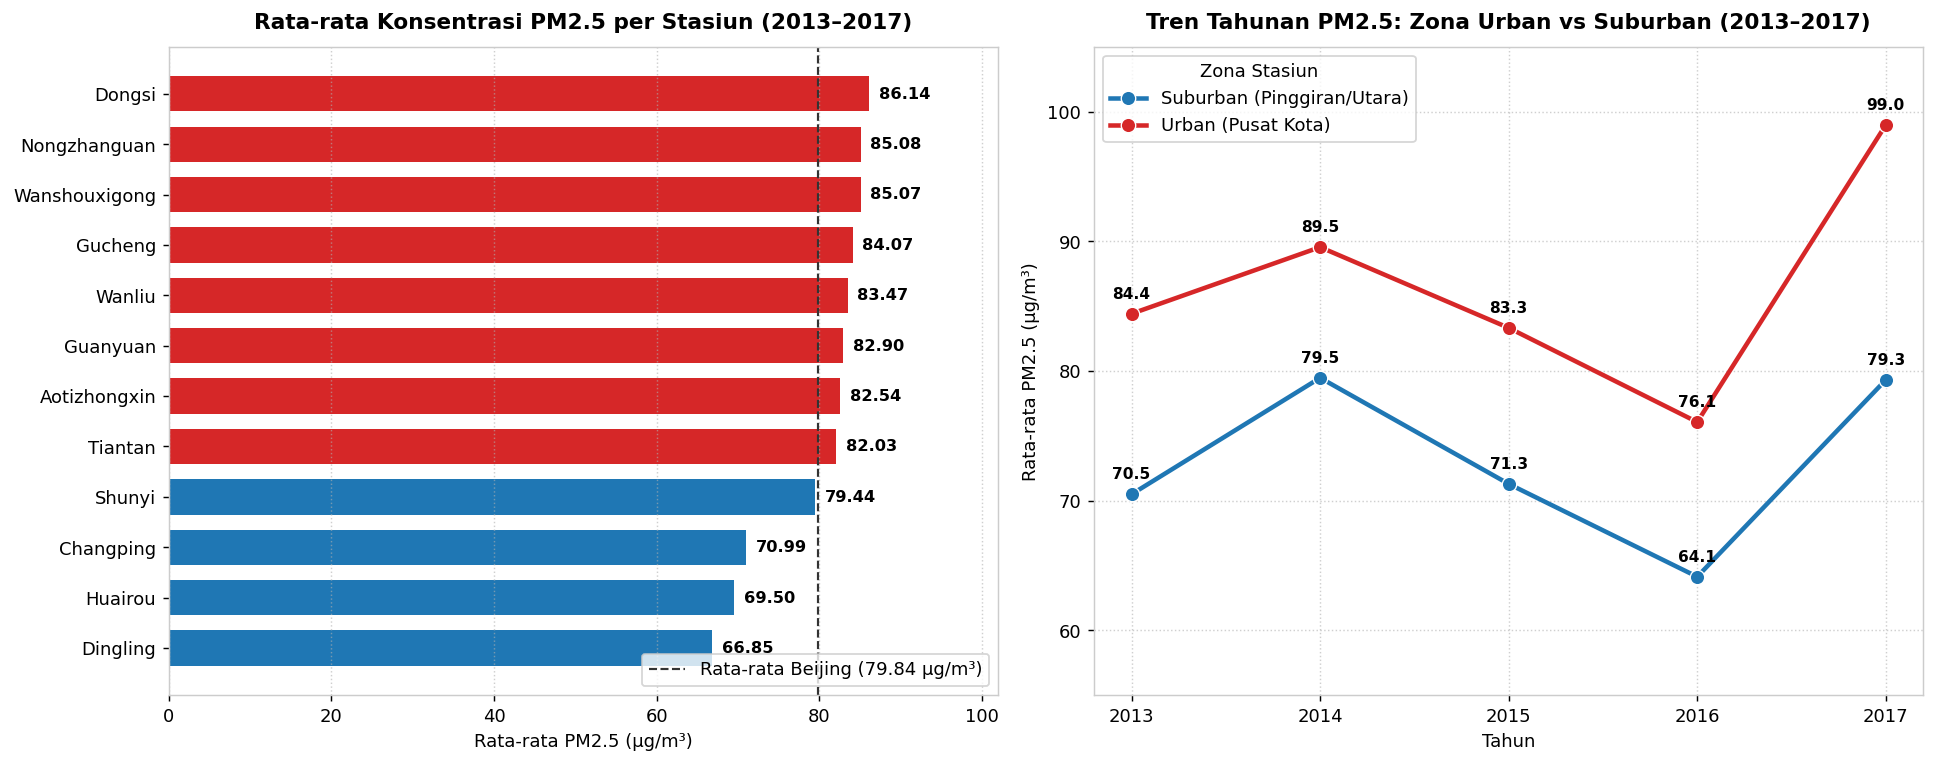

In [9]:
# Visualisasi Pertanyaan 1: Peringkat 12 Stasiun & Tren Tahunan Zona Urban vs Suburban
st_agg = df_clean.groupby(['station', 'station_zone'], as_index=False).agg(
    PM25_mean=('PM2.5', 'mean'),
    PM10_mean=('PM10', 'mean')
).sort_values('PM25_mean', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors1 = ['#1f77b4' if z == 'Suburban (Pinggiran/Utara)' else '#d62728' for z in st_agg['station_zone']]
bars = axes[0].barh(st_agg['station'], st_agg['PM25_mean'], color=colors1, height=0.7)
axes[0].axvline(df_clean['PM2.5'].mean(), color='#333333', linestyle='--', linewidth=1.2,
                label=f"Rata-rata Beijing ({df_clean['PM2.5'].mean():.2f} µg/m³)")
for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 1.2, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', fontsize=9, fontweight='bold')
axes[0].set_xlim(0, 102)
axes[0].set_title("Rata-rata Konsentrasi PM2.5 per Stasiun (2013–2017)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Rata-rata PM2.5 (µg/m³)")
axes[0].legend(loc='lower right')

yr_zone = df_clean.groupby(['year', 'station_zone'], as_index=False)['PM2.5'].mean()
sns.lineplot(data=yr_zone, x='year', y='PM2.5', hue='station_zone', marker='o', linewidth=2.5, markersize=8,
             palette={'Urban (Pusat Kota)': '#d62728', 'Suburban (Pinggiran/Utara)': '#1f77b4'}, ax=axes[1])
axes[1].set_xticks([2013, 2014, 2015, 2016, 2017])
axes[1].set_title("Tren Tahunan PM2.5: Zona Urban vs Suburban (2013–2017)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Rata-rata PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

**Explanatory Insight Pertanyaan 1:**
- Seluruh **8 stasiun di zona Urban (Pusat Kota)** menempati peringkat teratas polusi `PM2.5`, dipimpin oleh **Dongsi (`86.14 µg/m³`)**, **Nongzhanguan (`85.08 µg/m³`)**, dan **Wanshouxigong (`85.07 µg/m³`)**.
- Sebaliknya, **4 stasiun di zona Suburban (Pinggiran/Utara)** memiliki udara yang jauh lebih bersih, dengan **Dingling (`66.85 µg/m³`)**, **Huairou (`69.50 µg/m³`)**, dan **Changping (`70.99 µg/m³`)** sebagai lokasi paling rendah polusi.
- Secara agregat, rata-rata `PM2.5` di zona **Urban (`83.91 µg/m³`)** lebih tinggi **17,05%** dibandingkan zona **Suburban (`71.69 µg/m³`)**, dan konsentrasi `NO2` (indikator utama emisi kendaraan bermotor) di zona Urban (`57.44 µg/m³`) lebih tinggi **55,58%** dibandingkan zona Suburban (`36.92 µg/m³`).

### Pertanyaan 2: Pola Musiman (Bulanan) dan Jam Sibuk Harian (Diurnal Cycle)

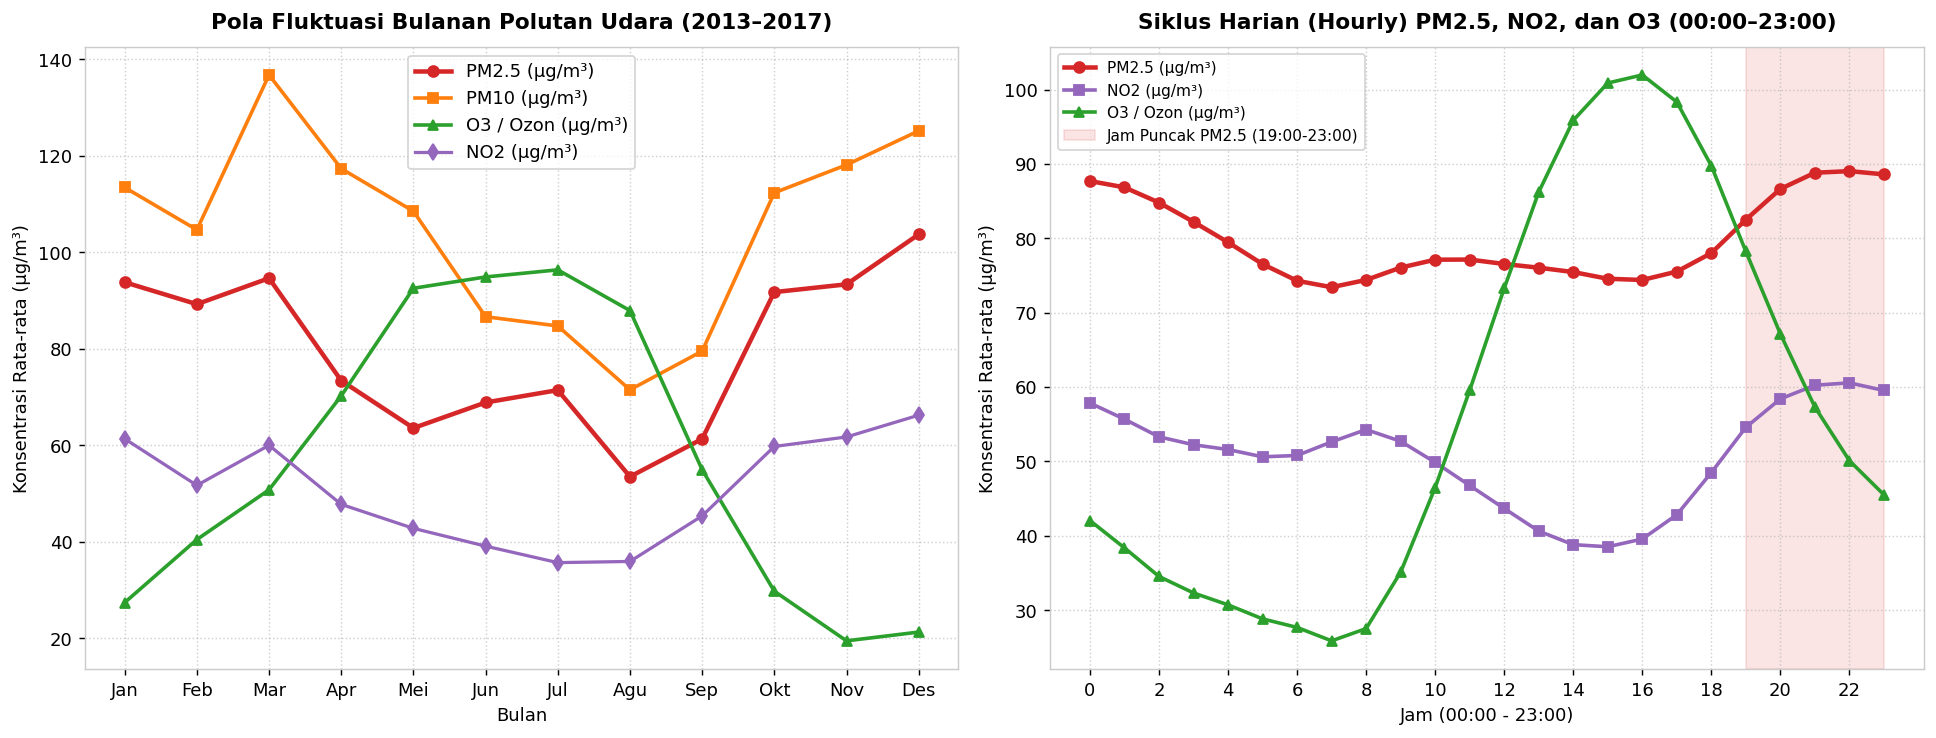

In [10]:
# Visualisasi Pertanyaan 2: Pola Bulanan (Musiman) dan Siklus Harian 24 Jam
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
m_agg = df_clean.groupby('month', as_index=False)[['PM2.5', 'PM10', 'O3', 'NO2']].mean()
axes[0].plot(m_agg['month'], m_agg['PM2.5'], marker='o', linewidth=2.5, color='#d62728', label='PM2.5 (µg/m³)')
axes[0].plot(m_agg['month'], m_agg['PM10'], marker='s', linewidth=2.0, color='#ff7f0e', label='PM10 (µg/m³)')
axes[0].plot(m_agg['month'], m_agg['O3'], marker='^', linewidth=2.0, color='#2ca02c', label='O3 / Ozon (µg/m³)')
axes[0].plot(m_agg['month'], m_agg['NO2'], marker='d', linewidth=1.8, color='#9467bd', label='NO2 (µg/m³)')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])
axes[0].set_title("Pola Fluktuasi Bulanan Polutan Udara (2013–2017)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Konsentrasi Rata-rata (µg/m³)")
axes[0].legend()

h_agg = df_clean.groupby('hour', as_index=False)[['PM2.5', 'NO2', 'O3']].mean()
axes[1].plot(h_agg['hour'], h_agg['PM2.5'], marker='o', linewidth=2.5, color='#d62728', label='PM2.5 (µg/m³)')
axes[1].plot(h_agg['hour'], h_agg['NO2'], marker='s', linewidth=2.0, color='#9467bd', label='NO2 (µg/m³)')
axes[1].plot(h_agg['hour'], h_agg['O3'], marker='^', linewidth=2.0, color='#2ca02c', label='O3 / Ozon (µg/m³)')
axes[1].axvspan(19, 23, color='#d62728', alpha=0.12, label='Jam Puncak PM2.5 (19:00-23:00)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title("Siklus Harian (Hourly) PM2.5, NO2, dan O3 (00:00–23:00)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Jam (00:00 - 23:00)")
axes[1].set_ylabel("Konsentrasi Rata-rata (µg/m³)")
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Explanatory Insight Pertanyaan 2:**
- **Pola Musiman membentuk kurva huruf U (U-shaped curve) untuk partikulat (`PM2.5` & `PM10`):** Konsentrasi `PM2.5` memuncak pada **Musim Dingin / Winter (`95.74 µg/m³`)**, dengan bulan **Desember (`103.68 µg/m³`)** dan **Januari (`93.76 µg/m³`)** sebagai titik tertinggi akibat penggunaan batu bara untuk pemanas sentral dan fenomena inversi suhu dingin (`-0.34 °C`). Sebaliknya, `PM2.5` mencapai titik terendah pada **Musim Panas / Summer (`64.52 µg/m³`, Agustus `53.47 µg/m³`)**.
- **Pola Kebalikan pada Ozon (`O3`):** Konsentrasi `O3` justru memuncak pada **Musim Panas (`93.00 µg/m³`, Juli `96.33 µg/m³`)** dan **siang-sore hari (pukul 15:00–16:00 mencapai `100.88–101.96 µg/m³`)** karena reaksi fotokimia radiasi matahari terhadap `NOx` dan `VOC`.
- **Siklus Harian (Diurnal):** `PM2.5` dan `NO2` meningkat tajam mulai pukul **18:00** dan mencapai puncaknya pada pukul **21:00–22:00 (`88.81–89.03 µg/m³`)** akibat akumulasi emisi jam pulang kerja, masuknya truk angkutan berat ke dalam kota pada malam hari, serta menyempitnya lapisan batas atmosfer (*planetary boundary layer*) saat suhu malam turun.

### Pertanyaan 3: Pengaruh Faktor Meteorologi terhadap Penurunan Konsentrasi PM2.5

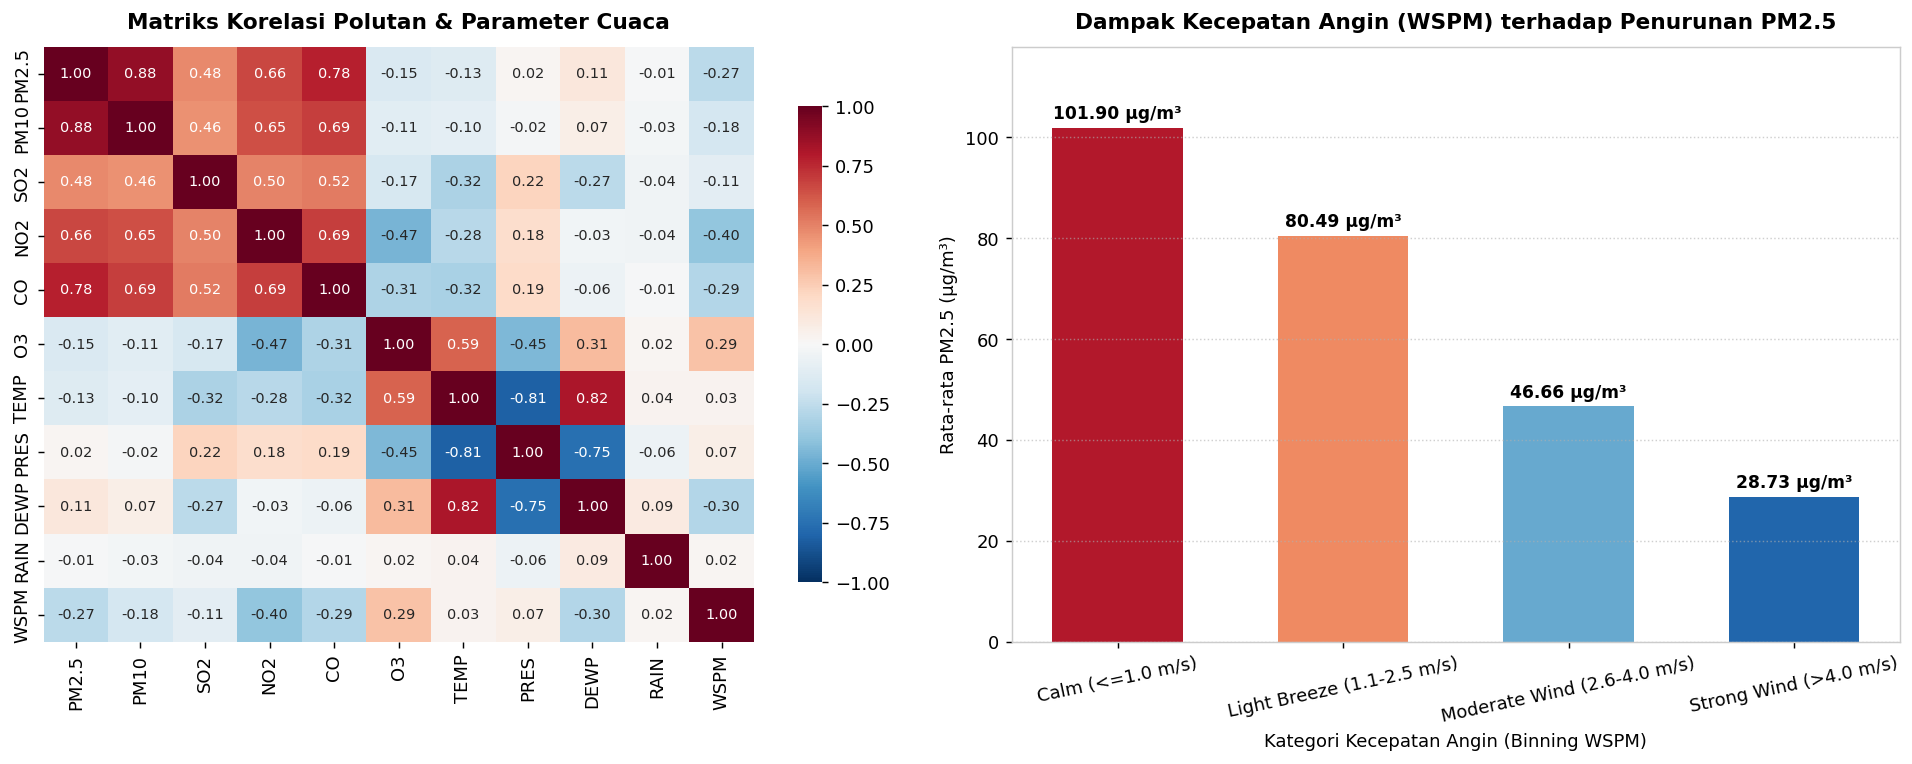

In [11]:
# Visualisasi Pertanyaan 3: Heatmap Korelasi & Dampak Rezim Kecepatan Angin (WSPM)
bins_wspm = [-np.inf, 1.0, 2.5, 4.0, np.inf]
labels_wspm = ['Calm (<=1.0 m/s)', 'Light Breeze (1.1-2.5 m/s)', 'Moderate Wind (2.6-4.0 m/s)', 'Strong Wind (>4.0 m/s)']
df_clean['wind_category'] = pd.cut(df_clean['WSPM'], bins=bins_wspm, labels=labels_wspm)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
corr_mat = df_clean[num_cols].corr()
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[0], annot_kws={'size': 8})
axes[0].set_title("Matriks Korelasi Polutan & Parameter Cuaca", fontsize=12, fontweight='bold')

wind_agg = df_clean.groupby('wind_category', observed=False, as_index=False)['PM2.5'].mean()
w_colors = ['#b2182b', '#ef8a62', '#67a9cf', '#2166ac']
wbars = axes[1].bar(wind_agg['wind_category'], wind_agg['PM2.5'], color=w_colors, width=0.58)
for b in wbars:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 1.8, f"{h:.2f} µg/m³", ha='center', fontsize=9.5, fontweight='bold')
axes[1].set_ylim(0, 118)
axes[1].set_title("Dampak Kecepatan Angin (WSPM) terhadap Penurunan PM2.5", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Kategori Kecepatan Angin (Binning WSPM)")
axes[1].set_ylabel("Rata-rata PM2.5 (µg/m³)")
axes[1].tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

**Explanatory Insight Pertanyaan 3:**
- Kecepatan angin (`WSPM`) memiliki korelasi negatif paling signifikan terhadap `PM2.5` (`r = -0.271`), `CO` (`r = -0.290`), dan `NO2` (`r = -0.396`).
- Ketika kondisi udara tenang (**Calm `<= 1.0 m/s`**), polutan terperangkap di permukaan kota sehingga rata-rata `PM2.5` melonjak hingga **`101.90 µg/m³`**. Saat kecepatan angin meningkat ke kategori **Moderate Wind (`2.6–4.0 m/s`)**, rata-rata `PM2.5` turun lebih dari separuhnya menjadi **`46.66 µg/m³`**, dan pada **Strong Wind (`> 4.0 m/s`)** turun drastis sebesar **71,81%** menjadi hanya **`28.73 µg/m³`**.

## Analisis Lanjutan (Tanpa Algoritma Machine Learning)

Untuk memperkaya analisis secara mendalam tanpa menggunakan algoritma *Machine Learning*, kita menerapkan dua teknik analisis lanjutan yang relevan dengan karakteristik **Air Quality Dataset**:
1. **Clustering menggunakan metode Binning & Manual Grouping**: Mengelompokkan observasi berdasarkan ambang batas standar baku mutu indeks kualitas udara (**[US EPA PM2.5 AQI Breakpoints](https://www.epa.gov/sites/default/files/2016-04/documents/2012_aqi_factsheet.pdf)** / **[Revised PM2.5 AQI Breakpoints](https://aqicn.org/faq/2013-09-09/revised-pm25-aqi-breakpoints/)**: *Good `0–12.0`, Moderate `12.1–35.4`, Unhealthy for Sensitive Groups `35.5–55.4`, Unhealthy `55.5–150.4`, Very Unhealthy `150.5–250.4`, Hazardous `>250.4 µg/m³`*) untuk memetakan profil risiko kesehatan masyarakat di tiap stasiun.
2. **Geospatial Analysis**: Memetakan titik koordinat geografis (*Latitude* dan *Longitude*) ke-12 stasiun pemantauan di Beijing untuk melihat gradien spasial penyebaran polutan dari selatan/pusat kota menuju pegunungan utara.

=== HASIL CLUSTERING (BINNING) KATEGORI KUALITAS UDARA (AQI PM2.5) ===
                                     Jumlah Jam Observasi  Proporsi (%)
aqi_category                                                           
Good (0-12)                                         63914         15.19
Moderate (12.1-35.4)                                93063         22.12
Unhealthy for Sensitive (35.5-55.4)                 54487         12.95
Unhealthy (55.5-150.4)                             145458         34.57
Very Unhealthy (150.5-250.4)                        44950         10.68
Hazardous (>250.4)                                  18896          4.49

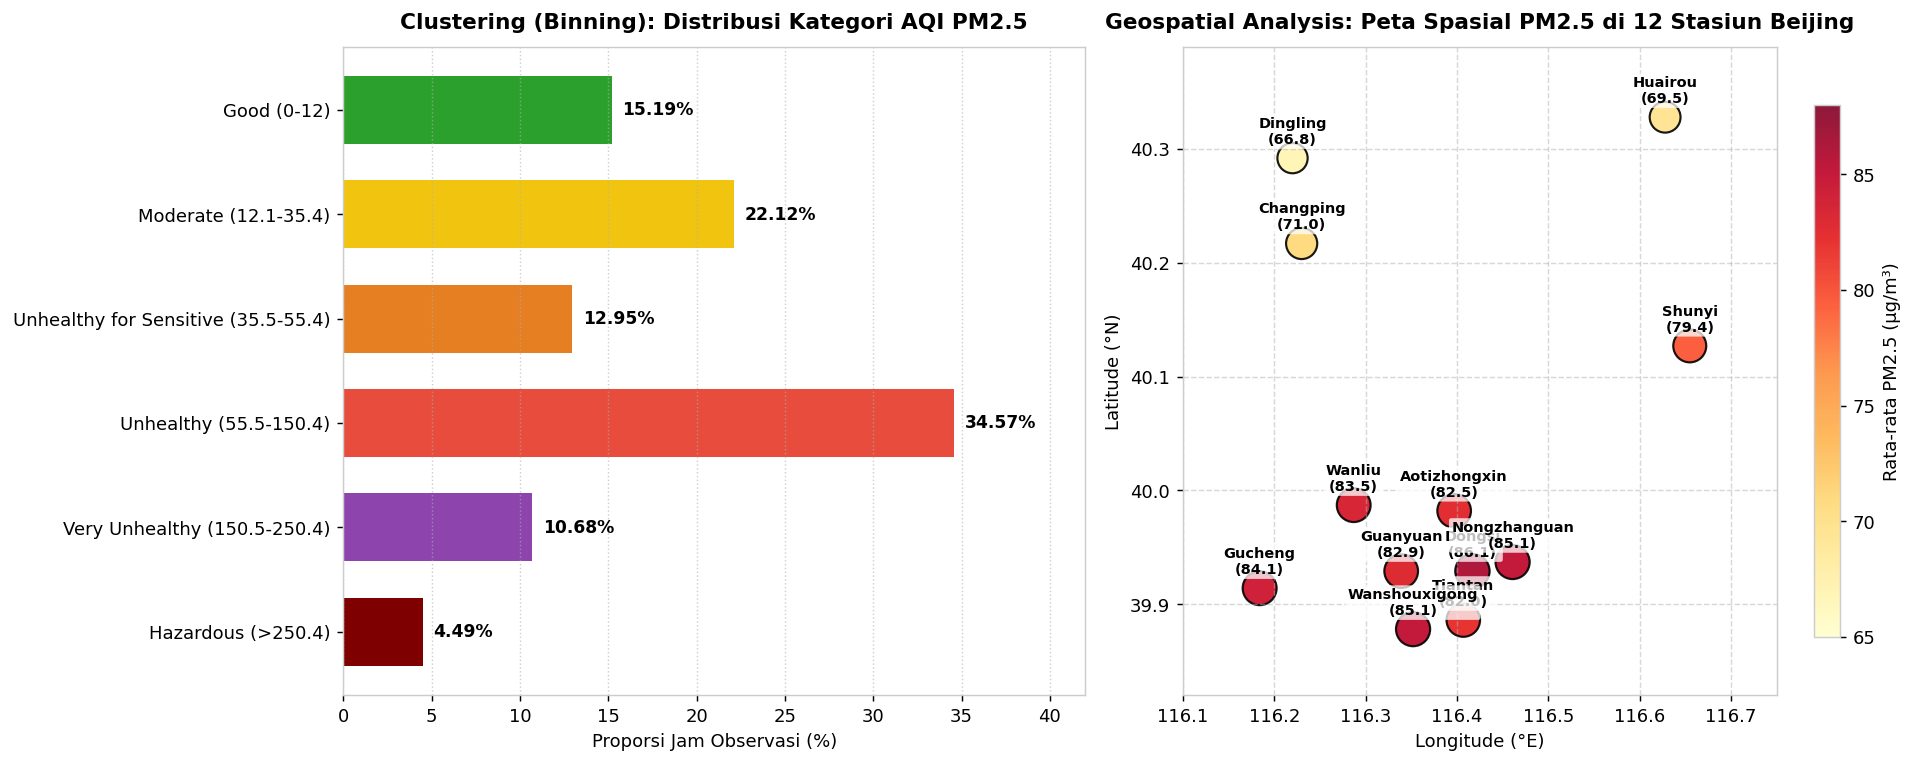

In [12]:
# 1. Clustering dengan Binning berdasarkan standar ambang batas AQI PM2.5
bins_pm25 = [-np.inf, 12.0, 35.4, 55.4, 150.4, 250.4, np.inf]
labels_pm25 = [
    'Good (0-12)',
    'Moderate (12.1-35.4)',
    'Unhealthy for Sensitive (35.5-55.4)',
    'Unhealthy (55.5-150.4)',
    'Very Unhealthy (150.5-250.4)',
    'Hazardous (>250.4)'
]
df_clean['aqi_category'] = pd.cut(df_clean['PM2.5'], bins=bins_pm25, labels=labels_pm25)

# 2. Menambahkan koordinat Geospasial 12 Stasiun Beijing
station_coords = {
    'Aotizhongxin': (39.982, 116.397), 'Changping': (40.217, 116.230),
    'Dingling': (40.292, 116.220),     'Dongsi': (39.929, 116.417),
    'Guanyuan': (39.929, 116.339),     'Gucheng': (39.914, 116.184),
    'Huairou': (40.328, 116.628),      'Nongzhanguan': (39.937, 116.461),
    'Shunyi': (40.127, 116.655),       'Tiantan': (39.886, 116.407),
    'Wanliu': (39.987, 116.287),       'Wanshouxigong': (39.878, 116.352)
}
df_clean['lat'] = df_clean['station'].map(lambda x: station_coords[x][0])
df_clean['lon'] = df_clean['station'].map(lambda x: station_coords[x][1])

# Menampilkan tabel proporsi kategori AQI dan memvisualisasikan Clustering + Geospatial Map
aqi_summary = pd.DataFrame({
    'Jumlah Jam Observasi': df_clean['aqi_category'].value_counts().reindex(labels_pm25),
    'Proporsi (%)': (df_clean['aqi_category'].value_counts(normalize=True).reindex(labels_pm25) * 100).round(2)
})
print("=== HASIL CLUSTERING (BINNING) KATEGORI KUALITAS UDARA (AQI PM2.5) ===")
print(aqi_summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
aqi_colors = ['#2ca02c', '#f1c40f', '#e67e22', '#e74c3c', '#8e44ad', '#7f0000']
abars = axes[0].barh(aqi_summary.index, aqi_summary['Proporsi (%)'], color=aqi_colors, height=0.65)
for b in abars:
    w = b.get_width()
    axes[0].text(w + 0.6, b.get_y() + b.get_height()/2, f"{w:.2f}%", va='center', fontsize=9.5, fontweight='bold')
axes[0].set_xlim(0, 42)
axes[0].invert_yaxis()
axes[0].set_title("Clustering (Binning): Distribusi Kategori AQI PM2.5", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Proporsi Jam Observasi (%)")

geo_df = df_clean.groupby(['station', 'station_zone', 'lat', 'lon'], as_index=False).agg(PM25=('PM2.5', 'mean'))
scatter = axes[1].scatter(
    geo_df['lon'], geo_df['lat'], c=geo_df['PM25'], cmap='YlOrRd', s=geo_df['PM25']*4.2,
    edgecolors='black', linewidth=1.2, alpha=0.9, vmin=65, vmax=88
)
for _, r in geo_df.iterrows():
    axes[1].annotate(f"{r['station']}\n({r['PM25']:.1f})", (r['lon'], r['lat']),
                     textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8, fontweight='bold')
plt.colorbar(scatter, ax=axes[1], shrink=0.82, label="Rata-rata PM2.5 (µg/m³)")
axes[1].set_xlim(116.10, 116.75)
axes[1].set_ylim(39.82, 40.39)
axes[1].set_title("Geospatial Analysis: Peta Spasial PM2.5 di 12 Stasiun Beijing", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
plt.tight_layout()
plt.show()

## Conclusion & Recommendation

### Conclusion
1. **Kesimpulan Pertanyaan 1 (Perbandingan Spasial Stasiun & Zona Wilayah):**
   - Stasiun dengan rata-rata polusi `PM2.5` tertinggi sepanjang Maret 2013 – Februari 2017 adalah **Dongsi (`86.14 µg/m³`)**, **Nongzhanguan (`85.08 µg/m³`)**, dan **Wanshouxigong (`85.07 µg/m³`)**, di mana lebih dari **51,8%–53,1%** jam observasinya berada pada level tidak sehat (`PM2.5 > 55.4 µg/m³`). Sebaliknya, stasiun paling bersih berada di bagian utara, yaitu **Dingling (`66.85 µg/m³`)**, **Huairou (`69.50 µg/m³`)**, dan **Changping (`70.99 µg/m³`)**.
   - Zona **Urban (Pusat Kota, 8 stasiun)** memiliki rata-rata `PM2.5` sebesar **`83.91 µg/m³`**, atau **17,05% lebih tinggi** dibandingkan zona **Suburban (`71.69 µg/m³`)**, serta memiliki rata-rata `NO2` **55,58% lebih tinggi** (`57.44` vs `36.92 µg/m³`). Untuk tahun kalender penuh (2014–2016), rata-rata `PM2.5` berhasil turun sebesar **16,36%** (dari `86.18 µg/m³` pada 2014 menjadi `72.08 µg/m³` pada 2016).

2. **Kesimpulan Pertanyaan 2 (Pola Musiman & Jam Kritis Harian):**
   - Polusi partikulat (`PM2.5`) mencapai level paling parah pada **Musim Dingin / Winter (Desember–Februari)** dengan rata-rata **`95.74 µg/m³`** dan puncaknya pada bulan **Desember (`103.68 µg/m³`, CO `2,112.77 µg/m³`)**—atau **48,39% lebih tinggi** dibandingkan **Musim Panas / Summer (`64.52 µg/m³`, terendah Agustus `53.47 µg/m³`)**. Sebaliknya, polutan sekunder **Ozon (`O3`)** mencapai puncak tertinggi di **Musim Panas (`93.00 µg/m³`)**.
   - Dalam siklus 24 jam harian, konsentrasi `PM2.5` dan `NO2` memuncak pada malam hari pukul **21:00–22:00 (`88.81–89.03 µg/m³`)** dan mencapai titik terendah pada pagi hari pukul **06:00–07:00 (`73.42–74.29 µg/m³`)** serta sore hari pukul **15:00–16:00 (`74.40–74.56 µg/m³`)**.

3. **Kesimpulan Pertanyaan 3 & Analisis Lanjutan (Dampak Meteorologi, Clustering AQI, & Geospasial):**
   - Kecepatan angin (`WSPM`) memiliki korelasi negatif terkuat terhadap `PM2.5` (`r = -0.271`). Hasil *Clustering Binning* membuktikan bahwa saat kondisi angin tenang (**Calm `<= 1.0 m/s`**), rata-rata `PM2.5` mencapai **`101.90 µg/m³`**, namun turun drastis sebesar **71,81%** menjadi **`28.73 µg/m³`** saat angin kencang (**Strong Wind `> 4.0 m/s`**).
   - Secara keseluruhan, hasil *Clustering Binning AQI* menunjukkan bahwa **49,74%** waktu observasi di Beijing berada pada kategori tidak sehat bagi publik (*Unhealthy* `34,57%`, *Very Unhealthy* `10,68%`, dan *Hazardous* `4,49%`), dengan gradien geospasial yang memusat di koridor selatan dan pusat kota.

---

### Recommendation (Action Items)
1. **Pengetatan Zona Rendah Emisi (*Low Emission Zone*) & Pembatasan Kendaraan Berat Malam Hari di 8 Stasiun Urban:**
   - Pemerintah daerah perlu memprioritaskan pembatasan lalu lintas kendaraan berbahan bakar fosil dan memperketat pengawasan emisi truk logistik pada rentang jam **18:00–23:00** di distrik pusat kota (**Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, dan Wanliu**) untuk menekan lonjakan malam hari pada `PM2.5` dan `NO2`.
2. **Transisi Pemanas Ruangan Ramah Lingkungan (*Coal-to-Gas/Electric*) Menjelang Musim Gugur–Dingin (Oktober–Februari):**
   - Mengingat lonjakan `PM2.5` (`103.68 µg/m³`) dan `CO` (`2,112.77 µg/m³`) pada bulan November–Januari, intervensi subsidi konversi pemanas batu bara ke gas/listrik serta inspeksi boiler industri wajib diaktifkan mulai bulan **Oktober** sebelum suhu turun di bawah `0 °C`.
3. **Sistem Peringatan Dini (*Early Warning System*) Berbasis Prakiraan Kecepatan Angin (`WSPM <= 1.0 m/s`):**
   - Mengintegrasikan data meteorologi ke dalam protokol darurat polusi: apabila prakiraan cuaca memprediksi kondisi angin *Calm* (`WSPM <= 1.0 m/s`) selama lebih dari 12 jam berturut-turut, otoritas harus menerapkan *pre-emptive curtailment* (pengurangan kapasitas produksi pabrik sementara) dan mengeluarkan imbauan penggunaan masker respirator (N95/KN95) serta pembersih udara (*air purifier*) dalam ruangan bagi warga.
4. **Panduan Waktu Aktivitas Luar Ruang bagi Masyarakat:**
   - Masyarakat diimbau menjadwalkan olahraga atau aktivitas luar ruang pada pukul **06:00–08:00 pagi** (saat `PM2.5` dan `O3` sama-sama rendah) serta menghindari aktivitas luar ruang intensif pada malam hari (**20:00–23:00**, puncak `PM2.5`) maupun siang terik di musim panas (**14:00–16:00**, puncak `O3`).